# Protocol

## Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsRegressor
from sklearn.linear_model import LinearRegression, Lasso, Ridge
from sklearn.model_selection import cross_validate
from sklearn.metrics import mean_squared_error, mean_absolute_error
from sklearn.inspection import permutation_importance
from sklearn import preprocessing
from sklearn.model_selection import TimeSeriesSplit
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import Pipeline

## Import and Tidy Data

In [2]:
df_train_y = pd.read_csv('data/Datasets_MLready/y_train.csv')
df_train_y.head()

,NO2,O3,PM10
0,17.20,44.33,18.81
1,9.33,49.89,16.57
2,12.80,46.59,27.35
3,24.10,41.80,19.33
4,8.67,50.66,11.73


In [3]:
df_train_X = pd.read_csv('data/Datasets_MLready/X_train_transformed.csv')
df_train_X.head()

,Month_sin__Month,Month_cos__Month,Day_sin__Day,Day_cos__Day,Weekday_sin__Weekday,Weekday_cos__Weekday,Time_sin__Time,Time_cos__Time,Spline_month__Month_sp_0,Spline_month__Month_sp_1,...,encoded__Location_Zch_Rosengartenstrasse,encoded__Location_Zch_Schimmelstrasse,encoded__Location_Zch_Stampfenbachstrasse,scaled__Hr,scaled__RainDur,scaled__T,scaled__WVv,scaled__StrGlo,scaled__meanVehicles,remainder__Year
0,-2.449294e-16,1.000000,0.433884,-0.900969,-0.781831,0.62349,-0.258819,0.965926,0.166667,0.666667,...,1.0,0.0,0.0,-0.106724,-0.347905,-0.442934,1.127894,-0.617743,-0.145789,2018.0
1,-2.449294e-16,1.000000,0.433884,-0.900969,-0.781831,0.62349,-0.258819,0.965926,0.166667,0.666667,...,0.0,1.0,0.0,-0.286880,-0.347905,-0.369828,-0.105097,-0.617743,-0.563898,2018.0
2,-2.449294e-16,1.000000,0.433884,-0.900969,-0.781831,0.62349,-0.258819,0.965926,0.166667,0.666667,...,0.0,0.0,1.0,-0.162810,-0.347905,-0.437893,4.097794,-0.617743,-0.864052,2018.0
3,5.000000e-01,0.866025,0.781831,0.623490,0.000000,1.00000,0.000000,1.000000,0.033083,0.529225,...,1.0,0.0,0.0,0.016779,-0.328655,-0.410163,0.849131,-0.617786,0.887373,2018.0
4,5.000000e-01,0.866025,0.781831,0.623490,0.000000,1.00000,0.000000,1.000000,0.033083,0.529225,...,0.0,1.0,0.0,-0.110690,-0.347905,-0.378651,0.205832,-0.617786,0.029038,2018.0


In [4]:
# Select columns to create two separate datasets with different time-encodings (Trigonometric and Spline)
spline_cols = list(df_train_X.filter(like="Spline_").columns)
scaled_cols = list(df_train_X.filter(like="scaled_").columns)
encoded_cols = list(df_train_X.filter(like="encoded_").columns)
year_col = list(df_train_X.filter(like="remainder_").columns)
tri_cols = list(df_train_X.iloc[:,0:8].columns)

In [5]:
# plotting a pairplot
# df_pairplot = df.drop(columns=["Datetime", "Month", "Weekday", "YearMonth"])
#
# sns.set_theme(style="ticks")
#
# sns.pairplot(df_pairplot, hue="Location")

In [6]:
# df[["Month", "Weekday", "Year"]] = df[["Month", "Weekday", "Year"]].astype("category")
#
# df.dtypes

## 3. Time-based cross-validation

In [7]:
# fixed training set size
tss = TimeSeriesSplit(n_splits=5,gap=24*2,max_train_size=24 * 365,test_size=24*30)

## 4. Model Evaluation

In [43]:
# model evaluation
def evaluate(model, X, y):
    ret = cross_validate(model, X, y, cv=tss, scoring=["neg_root_mean_squared_error"])
    rmse = -ret["test_neg_root_mean_squared_error"]
    return rmse.mean(), rmse.std()

# Helper function to collect results
results_dict = {}
def add_result(results_dict, row_name, model_name, rmse, std):
    if row_name not in results_dict:
        results_dict[row_name] = {}
    results_dict[row_name][f"{model_name}_rmse"] = rmse
    results_dict[row_name][f"{model_name}_std"] = std

In [9]:
X_tri = df_train_X[encoded_cols + tri_cols + scaled_cols + year_col]
X_spl = df_train_X[encoded_cols + spline_cols + scaled_cols + year_col]

In [10]:
y_NO2 = df_train_y["NO2"]
y_O3 = df_train_y["O3"]
y_PM10 = df_train_y["PM10"]

In [11]:
df_train_y.describe()

,NO2,O3,PM10
count,171398.000000,171398.000000,171398.000000
mean,29.585936,45.986320,14.877335
std,17.374629,30.222047,9.619687
min,0.710000,-0.220000,-9.850000
25%,16.140000,21.350000,8.520000
50%,26.650000,44.960000,12.920000
75%,40.050000,66.140000,18.820000
max,308.120000,184.630000,593.440000


### Model 2 - Lasso

In [47]:
# Build and evaluate a basic model
alpha = 0.1
model_lasso = Lasso(alpha=alpha)

lasso_tri_NO2_rmse, lasso_tri_NO2_std = evaluate(model_lasso, X_tri, y_NO2)
lasso_spl_NO2_rmse, lasso_spl_NO2_std = evaluate(model_lasso, X_spl, y_NO2)
lasso_tri_O3_rmse, lasso_tri_O3_std = evaluate(model_lasso, X_tri, y_O3)
lasso_spl_O3_rmse, lasso_spl_O3_std = evaluate(model_lasso, X_spl, y_O3)
lasso_tri_PM10_rmse, lasso_tri_PM10_std = evaluate(model_lasso, X_tri, y_PM10)
lasso_spl_PM10_rmse, lasso_spl_PM10_std = evaluate(model_lasso, X_spl, y_PM10)

# Collect results for overview
add_result(results_dict, "tri_NO2", "lasso", lasso_tri_NO2_rmse, lasso_tri_NO2_std)
add_result(results_dict, "spl_NO2", "lasso", lasso_spl_NO2_rmse, lasso_spl_NO2_std)
add_result(results_dict, "tri_O3", "lasso", lasso_tri_O3_rmse, lasso_tri_O3_std)
add_result(results_dict, "spl_O3", "lasso", lasso_spl_O3_rmse, lasso_spl_O3_std)
add_result(results_dict, "tri_PM10", "lasso", lasso_tri_PM10_rmse, lasso_tri_PM10_std)
add_result(results_dict, "spl_PM10", "lasso", lasso_spl_PM10_rmse, lasso_spl_PM10_std)

# Print results
for row_name, metrics in results_dict.items():
    rmse = metrics.get("lasso_rmse")
    std = metrics.get("lasso_std")

    encoding, pollutant = row_name.split("_")
    encoding_name = "trigonometric" if encoding =="tri" else "spline"

    print(f"RMSE for Lasso, {encoding_name} encoding, {pollutant}: {rmse:.2f} ± {std:.2f}")

RMSE for Lasso, trigonometric encoding, NO2: 11.09 ± 3.55
RMSE for Lasso, spline encoding, NO2: 11.23 ± 3.41
RMSE for Lasso, trigonometric encoding, O3: 18.69 ± 3.38
RMSE for Lasso, spline encoding, O3: 18.29 ± 3.26
RMSE for Lasso, trigonometric encoding, PM10: 6.51 ± 0.73
RMSE for Lasso, spline encoding, PM10: 6.23 ± 0.33


### Model 3 - Ridge

In [33]:
# Build and evaluate a basic model
alpha = 0.1
model_ridge = Ridge(alpha=alpha)

ridge_tri_NO2_rmse, ridge_tri_NO2_std = evaluate(model_ridge, X_tri, y_NO2)
ridge_spl_NO2_rmse, ridge_spl_NO2_std = evaluate(model_ridge, X_spl, y_NO2)
ridge_tri_O3_rmse, ridge_tri_O3_std = evaluate(model_ridge, X_tri, y_O3)
ridge_spl_O3_rmse, ridge_spl_O3_std = evaluate(model_ridge, X_spl, y_O3)
ridge_tri_PM10_rmse, ridge_tri_PM10_std = evaluate(model_ridge, X_tri, y_PM10)
ridge_spl_PM10_rmse, ridge_spl_PM10_std = evaluate(model_ridge, X_spl, y_PM10)

# Make a list for easy print
evaluation_jobs = [
    ("ridge, trigonometric encoding, NO2", ridge_tri_NO2_rmse, ridge_tri_NO2_std),
    ("ridge, spline encoding, NO2", ridge_spl_NO2_rmse, ridge_spl_NO2_std),
    ("ridge, trigonometric encoding", ridge_tri_O3_rmse, ridge_tri_O3_std),
    ("ridge, spline encoding, O3", ridge_spl_O3_rmse, ridge_spl_O3_std),
    ("ridge, trigonometric encoding, PM10", ridge_tri_PM10_rmse, ridge_tri_PM10_std),
    ("ridge, spline encoding, PM10", ridge_spl_PM10_rmse, ridge_spl_PM10_std)
]

# Print results
for name, rmse, std in evaluation_jobs:
    print(f"RMSE for {name} is: {rmse:.2f} ± {std:.2f}")

RMSE for ridge, trigonometric encoding, NO2 is: 11.16 ± 3.46
RMSE for ridge, spline encoding, NO2 is: 11.19 ± 3.39
RMSE for ridge, trigonometric encoding is: 19.19 ± 3.26
RMSE for ridge, spline encoding, O3 is: 24.09 ± 11.56
RMSE for ridge, trigonometric encoding, PM10 is: 6.73 ± 1.43
RMSE for ridge, spline encoding, PM10 is: 8.87 ± 5.36


## 5. Feature selection

### Helper functions

In [14]:
# Build a grouping function
def group_features(feature_names):
    groups = {}
    for f in feature_names:
        # original variable name = prefix before first underscore
        base = f.split("__")[1].split("_")[0]
        groups.setdefault(base, []).append(f)
    return groups

# Compute grouped importance
def grouped_importance(model, X, y=None):
    # For Linear models
    if hasattr(model, "coef_"):
        raw = np.abs(model.coef_)
    # For pipeline with a linear model
    elif hasattr(model, "named_steps") and "linreg" in model.named_steps:
        raw = np.abs(model.named_steps["linreg"].coef_)
    # For Tree-based models
    elif hasattr(model, "feature_importances_"):
        raw = model.feature_importances_
    # Any other model without built-in importance
    else:
        if y is None:
            raise ValueError("y must be provided for models without built-in importance")
        # Sample from data, otherwise it is running very long
        X_sample = X.sample(5000, random_state=42)
        y_sample = y.loc[X_sample.index]
        permutation_result = permutation_importance(model, X_sample, y_sample, n_repeats=5, random_state=42)
        raw = permutation_result.importances_mean

    # Normalization
    normalized = raw / raw.sum()
    imp = pd.Series(normalized, index=X.columns)

    # Grouping
    groups = group_features(X.columns)
    grouped = {base: imp[cols].sum() for base, cols in groups.items()}

    return pd.Series(grouped).sort_values(ascending=False)

# Make grouped plots
def plot_grouped_importance(tri_imp, spl_imp, model_name, feature_name):
    """
    Plot grouped feature importance for trig vs spline models.
    tri_imp and spl_imp are the grouped importance Series.
    """
    df = pd.DataFrame({
        "Trig importance": tri_imp,
        "Spline importance": spl_imp
    }).fillna(0)

    # Reorder the features for visualisation
    feature_order = ["Year", "Month", "Weekday", "Time", "Day",
                     "Location",
                     "Hr", "RainDur", "T", "WVv", "StrGlo",
                     "meanVehicles"]

    df = df.reindex(feature_order)
    # Drop variables that are not present in this model (just in case of some pre-selection)
    df = df.dropna(how="all")

    plt.figure(figsize=(10, 6))
    ax = df.plot(kind="bar", width=0.8)
    # Add numeric labels on top of each bar
    for container in ax.containers:
        ax.bar_label(container, fmt="%.3f", padding=3, rotation=45, fontsize=6)

    plt.title(f"{model_name} Feature Importance (Grouped) – {feature_name}")
    plt.ylabel("Normalized Importance")
    plt.xlabel("Original Variable")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()

### Model 2 - Lasso

#### Feature importance analysis

In [15]:
# Train the models for the individual datasets
alpha = 0.1

lasso_tri_NO2 = Lasso(alpha=alpha).fit(X_tri, y_NO2)
lasso_spl_NO2 = Lasso(alpha=alpha).fit(X_spl, y_NO2)

lasso_tri_O3 = Lasso(alpha=alpha).fit(X_tri, y_O3)
lasso_spl_O3 = Lasso(alpha=alpha).fit(X_spl, y_O3)

lasso_tri_PM10 = Lasso(alpha=alpha).fit(X_tri, y_PM10)
lasso_spl_PM10 = Lasso(alpha=alpha).fit(X_spl, y_PM10)

# Build grouped importance tables for all 6 models
g_imp_lasso_tri_NO2 = grouped_importance(lasso_tri_NO2, X_tri)
g_imp_lasso_spl_NO2 = grouped_importance(lasso_spl_NO2, X_spl)

g_imp_lasso_tri_O3 = grouped_importance(lasso_tri_O3, X_tri)
g_imp_lasso_spl_O3 = grouped_importance(lasso_spl_O3, X_spl)

g_imp_lasso_tri_PM10 = grouped_importance(lasso_tri_PM10, X_tri)
g_imp_lasso_spl_PM10 = grouped_importance(lasso_spl_PM10, X_spl)

<Figure size 1000x600 with 0 Axes>

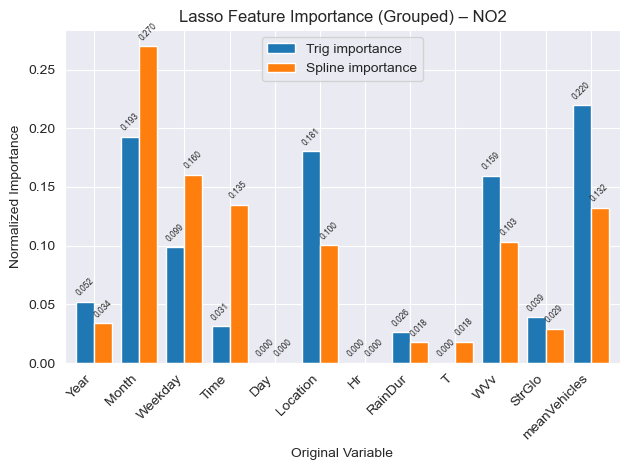

<Figure size 1000x600 with 0 Axes>

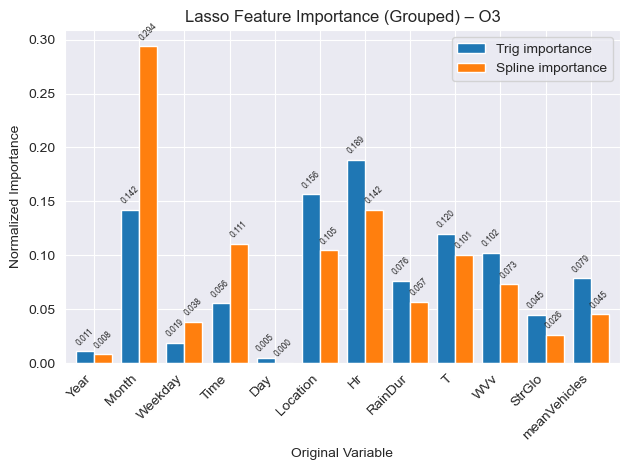

<Figure size 1000x600 with 0 Axes>

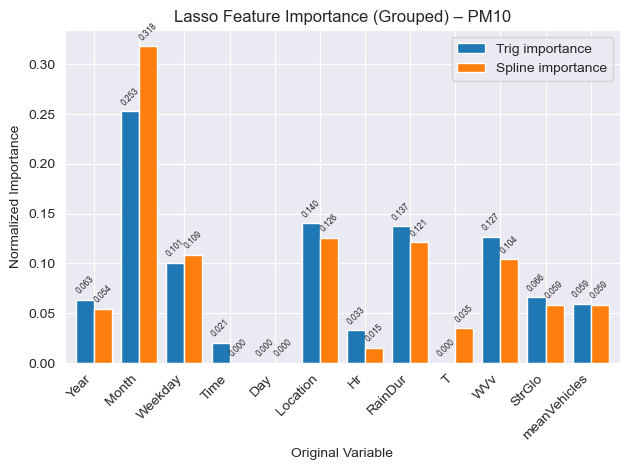

In [16]:
# Plot the grouped importance
plot_grouped_importance(g_imp_lasso_tri_NO2, g_imp_lasso_spl_NO2, "Lasso", "NO2")
plot_grouped_importance(g_imp_lasso_tri_O3,  g_imp_lasso_spl_O3, "Lasso", "O3")
plot_grouped_importance(g_imp_lasso_tri_PM10, g_imp_lasso_spl_PM10, "Lasso", "PM10")

#### Feature selection

No weather or traffic feature is standing out as clearly not important for all 3 pollutants. For this reason, we keep all features in the dataset for the Lasso model

### Model 3 - Ridge

#### Feature importance analysis

In [17]:
# Train the models for the individual datasets
alpha = 0.1

ridge_tri_NO2 = Ridge(alpha=alpha).fit(X_tri, y_NO2)
ridge_spl_NO2 = Ridge(alpha=alpha).fit(X_spl, y_NO2)

ridge_tri_O3 = Ridge(alpha=alpha).fit(X_tri, y_O3)
ridge_spl_O3 = Ridge(alpha=alpha).fit(X_spl, y_O3)

ridge_tri_PM10 = Ridge(alpha=alpha).fit(X_tri, y_PM10)
ridge_spl_PM10 = Ridge(alpha=alpha).fit(X_spl, y_PM10)

# Build grouped importance tables for all 6 models
g_imp_ridge_tri_NO2 = grouped_importance(ridge_tri_NO2, X_tri)
g_imp_ridge_spl_NO2 = grouped_importance(ridge_spl_NO2, X_spl)

g_imp_ridge_tri_O3 = grouped_importance(ridge_tri_O3, X_tri)
g_imp_ridge_spl_O3 = grouped_importance(ridge_spl_O3, X_spl)

g_imp_ridge_tri_PM10 = grouped_importance(ridge_tri_PM10, X_tri)
g_imp_ridge_spl_PM10 = grouped_importance(ridge_spl_PM10, X_spl)

<Figure size 1000x600 with 0 Axes>

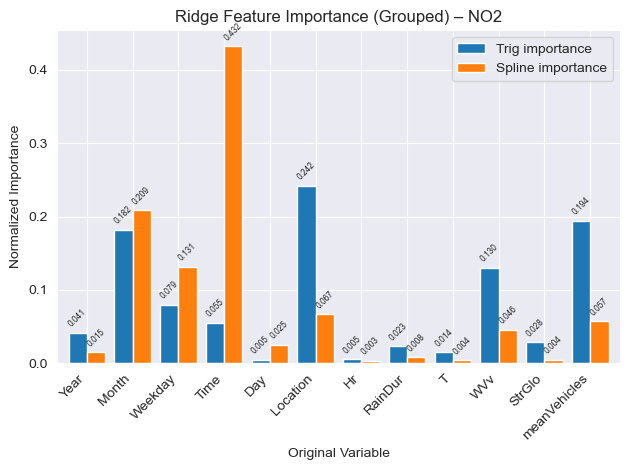

<Figure size 1000x600 with 0 Axes>

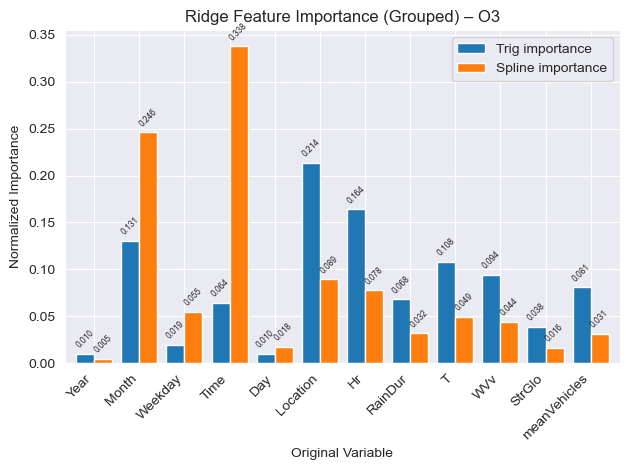

<Figure size 1000x600 with 0 Axes>

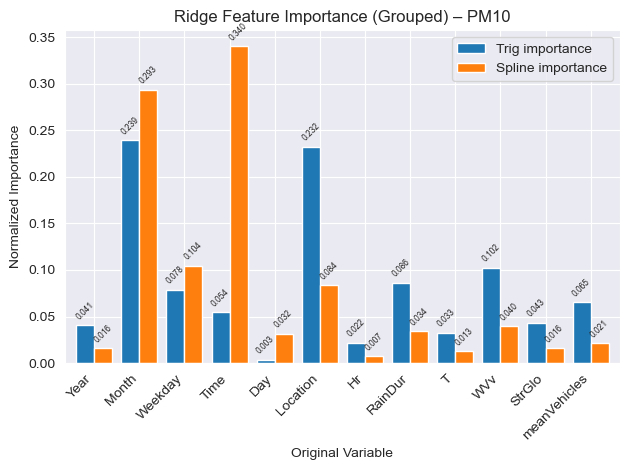

In [18]:
# Plot the grouped importance
plot_grouped_importance(g_imp_ridge_tri_NO2, g_imp_ridge_spl_NO2, "Ridge", "NO2")
plot_grouped_importance(g_imp_ridge_tri_O3,  g_imp_ridge_spl_O3, "Ridge", "O3")
plot_grouped_importance(g_imp_ridge_tri_PM10, g_imp_ridge_spl_PM10, "Ridge", "PM10")

#### Feature selection

No weather or traffic feature is standing out as clearly not important for all 3 pollutants. For this reason, we keep all features in the dataset for the Lasso model

## 6. Hyperparameter Tuning

### Model 2 - Lasso

In [19]:
# Find all hyperparams of the model
model_lasso = Lasso()
model_lasso.get_params()

{'alpha': 1.0,
 'copy_X': True,
 'fit_intercept': True,
 'max_iter': 1000,
 'positive': False,
 'precompute': False,
 'random_state': None,
 'selection': 'cyclic',
 'tol': 0.0001,
 'warm_start': False}

Since Lasso model contains only few hyperparameters to tune, we will use Grid search

In [20]:
# Use a full grid over hyperparameters with a helper function
def tune_lasso(X, y, tss):
    """
    Run hyperparameter tuning for a single Lasso model using TimeSeriesSplit.
    """
    model = Lasso()

    param_grid = {
        "alpha": [0.001, 0.01, 0.1, 0.5, 1, 5, 10],
        "fit_intercept": [True, False],
        "max_iter": [5000]
    }

    search = GridSearchCV(
        estimator=model,
        param_grid=param_grid,
        cv=tss,
        scoring="neg_root_mean_squared_error",
        n_jobs=-1
    )

    search.fit(X, y)
    return search

# Compare tuning between the 6 models
tuned_lasso_tri_NO2 = tune_lasso(X_tri, y_NO2, tss)
tuned_lasso_spl_NO2 = tune_lasso(X_spl, y_NO2, tss)

tuned_lasso_tri_O3 = tune_lasso(X_tri, y_O3, tss)
tuned_lasso_spl_O3 = tune_lasso(X_spl, y_O3, tss)

tuned_lasso_tri_PM10 = tune_lasso(X_tri, y_PM10, tss)
tuned_lasso_spl_PM10 = tune_lasso(X_spl, y_PM10, tss)

# Put them in a list for easy print
tuned_lasso_models = [
    ("NO2 – Trig", tuned_lasso_tri_NO2),
    ("NO2 – Spline", tuned_lasso_spl_NO2),
    ("O3 – Trig", tuned_lasso_tri_O3),
    ("O3 – Spline", tuned_lasso_spl_O3),
    ("PM10 – Trig", tuned_lasso_tri_PM10),
    ("PM10 – Spline", tuned_lasso_spl_PM10)
]

# Summarize result
for name, model in tuned_lasso_models:
    print(f"Model: {name}")
    print(f"Best Score: {model.best_score_}")
    print(f"Best Hyperparameters: {model.best_params_}")
    print()

Model: NO2 – Trig
Best Score: -11.089663003547487
Best Hyperparameters: {'alpha': 0.1, 'fit_intercept': True, 'max_iter': 5000}

Model: NO2 – Spline
Best Score: -10.904957652670957
Best Hyperparameters: {'alpha': 0.01, 'fit_intercept': True, 'max_iter': 5000}

Model: O3 – Trig
Best Score: -17.453407661931582
Best Hyperparameters: {'alpha': 1, 'fit_intercept': True, 'max_iter': 5000}

Model: O3 – Spline
Best Score: -17.273447150222957
Best Hyperparameters: {'alpha': 0.5, 'fit_intercept': True, 'max_iter': 5000}

Model: PM10 – Trig
Best Score: -6.2093176156536245
Best Hyperparameters: {'alpha': 0.5, 'fit_intercept': True, 'max_iter': 5000}

Model: PM10 – Spline
Best Score: -6.180739875628598
Best Hyperparameters: {'alpha': 0.5, 'fit_intercept': True, 'max_iter': 5000}



### Model 3 - Ridge

In [21]:
# Find all hyperparams of the model
model_lasso = Ridge()
model_lasso.get_params()

{'alpha': 1.0,
 'copy_X': True,
 'fit_intercept': True,
 'max_iter': None,
 'positive': False,
 'random_state': None,
 'solver': 'auto',
 'tol': 0.0001}

Since Ridge model contains only few hyperparameters to tune, we will use Grid search

In [22]:
# Use a full grid over hyperparameters with a helper function
def tune_ridge(X, y, tss):
    """
    Run hyperparameter tuning for a single Ridge model using TimeSeriesSplit.
    """
    model = Ridge()

    param_grid = {
        "alpha": [0.001, 0.01, 0.1, 0.5, 1, 5, 10],
        "fit_intercept": [True, False],
        "max_iter": [5000]
    }

    search = GridSearchCV(
        estimator=model,
        param_grid=param_grid,
        cv=tss,
        scoring="neg_root_mean_squared_error",
        n_jobs=-1
    )

    search.fit(X, y)
    return search

# Compare tuning between the 6 models
tuned_ridge_tri_NO2 = tune_ridge(X_tri, y_NO2, tss)
tuned_ridge_spl_NO2 = tune_ridge(X_spl, y_NO2, tss)

tuned_ridge_tri_O3 = tune_ridge(X_tri, y_O3, tss)
tuned_ridge_spl_O3 = tune_ridge(X_spl, y_O3, tss)

tuned_ridge_tri_PM10 = tune_ridge(X_tri, y_PM10, tss)
tuned_ridge_spl_PM10 = tune_ridge(X_spl, y_PM10, tss)

# Put them in a list for easy print
tuned_ridge_models = [
    ("NO2 – Trig", tuned_ridge_tri_NO2),
    ("NO2 – Spline", tuned_ridge_spl_NO2),
    ("O3 – Trig", tuned_ridge_tri_O3),
    ("O3 – Spline", tuned_ridge_spl_O3),
    ("PM10 – Trig", tuned_ridge_tri_PM10),
    ("PM10 – Spline", tuned_ridge_spl_PM10)
]

# Summarize result
for name, model in tuned_ridge_models:
    print(f"Model: {name}")
    print(f"Best Score: {model.best_score_}")
    print(f"Best Hyperparameters: {model.best_params_}")
    print()

Model: NO2 – Trig
Best Score: -11.149539549911704
Best Hyperparameters: {'alpha': 10, 'fit_intercept': True, 'max_iter': 5000}

Model: NO2 – Spline
Best Score: -10.8923255425401
Best Hyperparameters: {'alpha': 10, 'fit_intercept': True, 'max_iter': 5000}

Model: O3 – Trig
Best Score: -19.1016507130255
Best Hyperparameters: {'alpha': 10, 'fit_intercept': True, 'max_iter': 5000}

Model: O3 – Spline
Best Score: -18.06332775751101
Best Hyperparameters: {'alpha': 1, 'fit_intercept': False, 'max_iter': 5000}

Model: PM10 – Trig
Best Score: -6.6744312045239145
Best Hyperparameters: {'alpha': 10, 'fit_intercept': False, 'max_iter': 5000}

Model: PM10 – Spline
Best Score: -6.451579553539455
Best Hyperparameters: {'alpha': 10, 'fit_intercept': False, 'max_iter': 5000}



## 6.2 Model evaluation 02 - cross validation

### Model 2 - Lasso

In [48]:
# Evaluate models with tuned hyperparameters
lasso_tri_NO2_rmse, lasso_tri_NO2_std = evaluate(tuned_lasso_tri_NO2.best_estimator_, X_tri, y_NO2)
lasso_spl_NO2_rmse, lasso_spl_NO2_std = evaluate(tuned_lasso_spl_NO2.best_estimator_, X_spl, y_NO2)
lasso_tri_O3_rmse, lasso_tri_O3_std = evaluate(tuned_lasso_tri_O3.best_estimator_, X_tri, y_O3)
lasso_spl_O3_rmse, lasso_spl_O3_std = evaluate(tuned_lasso_spl_O3.best_estimator_, X_spl, y_O3)
lasso_tri_PM10_rmse, lasso_tri_PM10_std = evaluate(tuned_lasso_tri_PM10.best_estimator_, X_tri, y_PM10)
lasso_spl_PM10_rmse, lasso_spl_PM10_std = evaluate(tuned_lasso_spl_PM10.best_estimator_, X_spl, y_PM10)

# Collect results for overview
add_result(results_dict, "tri_NO2", "lasso", lasso_tri_NO2_rmse, lasso_tri_NO2_std)
add_result(results_dict, "spl_NO2", "lasso", lasso_spl_NO2_rmse, lasso_spl_NO2_std)
add_result(results_dict, "tri_O3", "lasso", lasso_tri_O3_rmse, lasso_tri_O3_std)
add_result(results_dict, "spl_O3", "lasso", lasso_spl_O3_rmse, lasso_spl_O3_std)
add_result(results_dict, "tri_PM10", "lasso", lasso_tri_PM10_rmse, lasso_tri_PM10_std)
add_result(results_dict, "spl_PM10", "lasso", lasso_spl_PM10_rmse, lasso_spl_PM10_std)

# Print results
for row_name, metrics in results_dict.items():
    rmse = metrics.get("lasso_rmse")
    std = metrics.get("lasso_std")

    encoding, pollutant = row_name.split("_")
    encoding_name = "trigonometric" if encoding =="tri" else "spline"

    print(f"RMSE for Lasso, {encoding_name} encoding, {pollutant}: {rmse:.2f} ± {std:.2f}")


RMSE for Lasso, trigonometric encoding, NO2: 11.09 ± 3.55
RMSE for Lasso, spline encoding, NO2: 10.90 ± 3.46
RMSE for Lasso, trigonometric encoding, O3: 17.45 ± 4.46
RMSE for Lasso, spline encoding, O3: 17.27 ± 4.19
RMSE for Lasso, trigonometric encoding, PM10: 6.21 ± 0.28
RMSE for Lasso, spline encoding, PM10: 6.18 ± 0.27


Using Lasso model, Spline encoding gives consistently, but only slightly better results. Out of the 3 pollutants, O3 is predicted with least accuracy and also highest variability.

### Model 3 - Ridge

In [38]:
# Evaluate models with tuned hyperparameters
ridge_tri_NO2_rmse, ridge_tri_NO2_std = evaluate(tuned_ridge_tri_NO2.best_estimator_, X_tri, y_NO2)
ridge_spl_NO2_rmse, ridge_spl_NO2_std = evaluate(tuned_ridge_spl_NO2.best_estimator_, X_spl, y_NO2)
ridge_tri_O3_rmse, ridge_tri_O3_std = evaluate(tuned_ridge_tri_O3.best_estimator_, X_tri, y_O3)
ridge_spl_O3_rmse, ridge_spl_O3_std = evaluate(tuned_ridge_spl_O3.best_estimator_, X_spl, y_O3)
ridge_tri_PM10_rmse, ridge_tri_PM10_std = evaluate(tuned_ridge_tri_PM10.best_estimator_, X_tri, y_PM10)
ridge_spl_PM10_rmse, ridge_spl_PM10_std = evaluate(tuned_ridge_spl_PM10.best_estimator_, X_spl, y_PM10)

# Make a list for easy print
evaluation_jobs = [
    ("ridge, trigonometric encoding, NO2", ridge_tri_NO2_rmse, ridge_tri_NO2_std),
    ("ridge, spline encoding, NO2", ridge_spl_NO2_rmse, ridge_spl_NO2_std),
    ("ridge, trigonometric encoding", ridge_tri_O3_rmse, ridge_tri_O3_std),
    ("ridge, spline encoding, O3", ridge_spl_O3_rmse, ridge_spl_O3_std),
    ("ridge, trigonometric encoding, PM10", ridge_tri_PM10_rmse, ridge_tri_PM10_std),
    ("ridge, spline encoding, PM10", ridge_spl_PM10_rmse, ridge_spl_PM10_std)
]

# Print results
for name, rmse, std in evaluation_jobs:
    print(f"RMSE for {name} is: {rmse:.2f} ± {std:.2f}")

RMSE for ridge, trigonometric encoding, NO2 is: 11.15 ± 3.46
RMSE for ridge, spline encoding, NO2 is: 10.89 ± 3.44
RMSE for ridge, trigonometric encoding is: 19.10 ± 3.28
RMSE for ridge, spline encoding, O3 is: 18.06 ± 3.29
RMSE for ridge, trigonometric encoding, PM10 is: 6.67 ± 1.33
RMSE for ridge, spline encoding, PM10 is: 6.45 ± 1.00


Using Ridge model, Spline encoding gives consistently, but only slightly better results. Out of the 3 pollutants, O3 is predicted with least accuracy, while NO2 prediction shows the highest variability.

## 7. Model Evaluation Metrics

averaged across CV splits during model selection
reported on the final test year (2025)
- RMSE
- MAE

## 8. Model Selection

Compare all models (e.g. linear regression, random forest, ...)

- Mean CV RMSE
- Stability across folds (standard deviation)
- Interpretability
- Computational complexity

In [49]:
# Compile an overview of models evaluation
df_result_overview = pd.DataFrame.from_dict(results_dict, orient="index")
df_result_overview

,lasso_rmse,lasso_std
tri_NO2,11.089663,3.545373
spl_NO2,10.904958,3.458131
tri_O3,17.453408,4.464913
spl_O3,17.273447,4.186270
tri_PM10,6.209318,0.282009
spl_PM10,6.180740,0.265836


## 9. Final Training and Testing

With the best model only, not all of them

- The selected model is refit on all training data (2018–2024)
- Predictions are generated for 2025
- Final performance is reported on the test set

### Model 1 (Multiple Linear Regression)

In [25]:
# fitting the model
model_lr.fit(X_tri, y_NO2)

NameError: name 'model_lr' is not defined

In [263]:
df_test_X = pd.read_csv("data/Datasets_MLready/X_test_transformed.csv")
df_test_y = pd.read_csv("data/Datasets_MLready/y_test.csv")

In [264]:
y_NO2_test = df_test_y["NO2"]
y_NO2_test.describe()

count    25853.000000
mean        23.773432
std         13.584978
min          0.690000
25%         13.380000
50%         21.790000
75%         31.970000
max         95.510000
Name: NO2, dtype: float64

In [265]:
X_tri_test = df_test_X[encoded_cols + tri_cols + scaled_cols]
X_spl_test = df_test_X[spline_cols + tri_cols + scaled_cols]

In [266]:
predictions = model_lr.predict(X_tri_test)

ValueError: The feature names should match those that were passed during fit.
Feature names seen at fit time, yet now missing:
- remainder__Year


In [19]:
# model evaluation
print('mean_squared_error:', mean_squared_error(y_NO2_test, predictions))
print('mean_absolute_error:', mean_absolute_error(y_NO2_test, predictions))

mean_squared_error: 144.96042374933515
mean_absolute_error: 9.889888824026027
